# 03 · Transformer Decoder-only (GPT) — huấn luyện từ đầu

Dịch máy được đưa về bài toán **mô hình ngôn ngữ có điều kiện**: chuỗi huấn luyện là
`<s> câu tiếng Anh <sep> câu tiếng Việt </s>`, mặt nạ nhân quả cho toàn chuỗi, **loss chỉ tính trên phần tiếng Việt**.
Khi dịch, đưa vào `<s> câu tiếng Anh <sep>` (đệm trái khi chạy theo batch) và sinh tiếp tới `</s>`.

Để so sánh **công bằng** với Encoder–Decoder (notebook 02): cùng tokenizer, cùng dữ liệu, cùng d_model / head / d_ff /
dropout, cùng chế độ huấn luyện; **số lớp GPT được chọn để tổng số tham số xấp xỉ bằng nhau**.

⏱️ Thời gian ước tính: tương đương notebook 02 (chuỗi dài hơn do ghép nguồn + đích).

> **Quy trình chống lỗi:** luôn chạy với `DRY_RUN = True` trước (vài phút, dữ liệu và mô hình tí hon, đi qua **mọi**
> dòng code). Khi không còn lỗi nào, đổi `DRY_RUN = False` rồi chọn **Runtime → Run all** để chạy thật.
> Kết quả chạy thử nằm riêng trong thư mục `dryrun/`, không lẫn với kết quả thật.

> **Nếu Colab mất kết nối / hết phiên:** mở lại notebook, **Run all**. Huấn luyện tự tiếp tục từ checkpoint gần nhất
> (lưu mỗi vài trăm bước trên Drive). Bản dịch đã sinh từ đúng checkpoint sẽ không bị dịch lại.

In [3]:
#@title ⚙️ Tham số
DRY_RUN = False
RUN_ABLATIONS = True          # thêm biến thể GPT dùng positional encoding hình sin
BEAMS_MAIN = [1, 4]
BEAM_DEFAULT = 4
TIME_BUDGET_HOURS = None

In [4]:
#@title 🔧 Kết nối Google Drive + nạp thư viện `envi_lib`
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
PROJECT_DIR = os.environ.get("ENVI_PROJECT_DIR", "/content/drive/MyDrive/NLP_Final_EnVi")
if not os.path.exists(os.path.join(PROJECT_DIR, "envi_lib", "__init__.py")):
    raise FileNotFoundError(f"Chưa có thư viện ở {PROJECT_DIR}/envi_lib — hãy chạy notebook 00_cai_dat.ipynb trước.")
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
from envi_lib.common import (Paths, set_seed, get_device, pick_amp_dtype, autocast_ctx, gpu_info, peak_gpu_mem_gb,
                             reset_peak_mem, free_memory, count_params, disk_free_gb, save_predictions,
                             prediction_is_current, save_json, load_json, read_lines, write_lines, fmt_seconds,
                             bf16_supported, check_lib_version, now_str)
check_lib_version("1.0.0")
paths = Paths(PROJECT_DIR, dry_run=DRY_RUN).make_all()
DEVICE = get_device()
print(f"📁 {paths.root}   |   DRY_RUN = {DRY_RUN}   |   thiết bị: {gpu_info()}")

Mounted at /content/drive
📁 /content/drive/MyDrive/NLP_Final_EnVi   |   DRY_RUN = False   |   thiết bị: {'cuda': True, 'torch': '2.11.0+cu130', 'name': 'NVIDIA L4', 'total_gb': 22.0, 'bf16': True}


In [5]:
%pip install -q sacrebleu sacremoses sentencepiece

In [6]:
import math, time, json, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from functools import partial
from envi_lib import data as D, models as MD, decoding as DEC, metrics as M, selftest
from envi_lib.train import TrainConfig, Trainer

AMP = pick_amp_dtype("auto")
print("GPU:", gpu_info(), "| autocast:", AMP)
if DEVICE.type != "cuda":
    if DRY_RUN:
        print("⚠️  Không có GPU — DRY_RUN vẫn chạy trên CPU (chậm hơn).")
    else:
        raise RuntimeError("Cần GPU: Runtime → Change runtime type → GPU")
print("Drive còn trống:", disk_free_gb(paths.root), "GB")
assert selftest.run_all(skip_slow=True), "Kiểm thử nhanh thất bại"

data = D.load_all_clean(paths, DRY_RUN)
tok = D.SpmTokenizer(paths.spm_model)
MAX_TOK = 150
tr_src, tr_tgt, n_drop = D.filter_by_token_len(tok.encode(data["train"][0]), tok.encode(data["train"][1]), MAX_TOK, MAX_TOK)
dev_src_txt, dev_ref = data["dev"]
test_src_txt, test_ref = data["test"]
dev_src_ids, dev_tgt_ids = tok.encode(dev_src_txt), tok.encode(dev_ref)
print(f"Train: {len(tr_src):,} cặp (bỏ {n_drop} cặp > {MAX_TOK} token) | dev: {len(dev_ref):,} | test: {len(test_ref):,} | vocab: {tok.vocab_size}")

GPU: {'cuda': True, 'torch': '2.11.0+cu130', 'name': 'NVIDIA L4', 'total_gb': 22.0, 'bf16': True} | autocast: torch.bfloat16
Drive còn trống: 183.6 GB
✅ Chuẩn hoá Unicode tiếng Việt
✅ Làm sạch dòng (HTML + detokenize)
✅ Batch theo số token, xác định theo epoch
✅ Ghép batch Seq2Seq / GPT (mặt nạ nhãn)
✅ Attention: SDPA == cài đặt thủ công
✅ Mặt nạ nhân quả (không nhìn tương lai)
✅ Bất biến với padding (kể cả đệm trái GPT)
✅ Beam search K=1 == greedy
✅ Beam search không kém greedy
✅ Dịch theo batch == dịch từng câu
✅ Label smoothing CE == PyTorch
✅ BLEU tự tính == sacreBLEU

🎉 TẤT CẢ KIỂM THỬ ĐỀU QUA
Train: 130,357 cặp (bỏ 43 cặp > 150 token) | dev: 1,500 | test: 1,268 | vocab: 16000


In [7]:
#@title 🏗️ Cấu hình mô hình & huấn luyện
# GPT dùng cùng d_model / số head / d_ff / dropout với Transformer Encoder-Decoder (notebook 02);
# số lớp được chọn để TỔNG SỐ THAM SỐ xấp xỉ bằng nhau => so sánh kiến trúc công bằng.
cfg_file = paths.checkpoints / "tf_base" / "config.json"
if cfg_file.exists():
    S2S = load_json(cfg_file)["model"]
    print("✔ Lấy cấu hình Encoder-Decoder từ notebook 02:", {k: S2S[k] for k in ("d_model", "enc_layers", "dec_layers")})
else:
    S2S = dict(d_model=64 if DRY_RUN else 512, n_heads=4, d_ff=128 if DRY_RUN else 1024,
               enc_layers=2 if DRY_RUN else 6, dec_layers=2 if DRY_RUN else 6, dropout=0.1 if DRY_RUN else 0.3,
               attn_dropout=0.1, activation="relu", pre_norm=True, max_len=512)
    print("ℹ️  Chưa chạy notebook 02 — dùng cấu hình mặc định.")
target_params = count_params(MD.TransformerSeq2Seq(MD.Seq2SeqConfig(**{**S2S, "vocab_size": tok.vocab_size})))
BASE_MODEL = dict(d_model=S2S["d_model"], n_heads=S2S["n_heads"], d_ff=S2S["d_ff"], dropout=S2S["dropout"],
                  attn_dropout=S2S["attn_dropout"], activation=S2S.get("activation", "relu"), pre_norm=True,
                  pos_encoding="learned", max_len=512)
BASE_MODEL["n_layers"] = MD.gpt_layers_to_match(target_params, MD.GPTConfig(vocab_size=tok.vocab_size, **BASE_MODEL))
BASE_TRAIN = dict(epochs=50, max_tokens=8192, lr=5e-4, warmup_steps=4000, schedule="inverse_sqrt",
                  label_smoothing=0.1, weight_decay=1e-4, clip_norm=1.0, patience=6, save_every_steps=1000,
                  log_every_steps=200)
EXPERIMENTS = {"gpt_base": dict(model={}, train={})}
if RUN_ABLATIONS:
    EXPERIMENTS["gpt_sinusoidal"] = dict(model=dict(pos_encoding="sinusoidal"), train={})
if DRY_RUN:
    BASE_TRAIN.update(epochs=2, max_tokens=2048, warmup_steps=50, save_every_steps=20, log_every_steps=10)
MAIN = "gpt_base"
m = MD.GPTDecoder(MD.GPTConfig(vocab_size=tok.vocab_size, **BASE_MODEL))
print(f"Encoder-Decoder: {target_params / 1e6:.1f}M tham số | GPT {BASE_MODEL['n_layers']} lớp: {count_params(m) / 1e6:.1f}M tham số")
del m

✔ Lấy cấu hình Encoder-Decoder từ notebook 02: {'d_model': 512, 'enc_layers': 6, 'dec_layers': 6}
Encoder-Decoder: 39.7M tham số | GPT 15 lớp: 40.0M tham số


In [8]:
collate = partial(D.gpt_collate, sep=tok.sep_id)

def loss_fn(model, b, cfg):
    logits = model(b["input_ids"], b["attn_mask"])
    return MD.label_smoothed_ce(logits, b["labels"], cfg.label_smoothing)   # chỉ tính loss trên phần câu đích

train_ds = D.PairDataset(tr_src, tr_tgt)
train_lengths = [len(s) + len(t) + 3 for s, t in zip(tr_src, tr_tgt)]

@torch.no_grad()
def dev_nll(model):
    model.eval(); tot = n = 0
    ds = D.PairDataset(dev_src_ids, dev_tgt_ids)
    for idx in D.sorted_eval_batches([len(s) + len(t) for s, t in zip(dev_src_ids, dev_tgt_ids)], 64):
        b = {k: v.to(DEVICE) for k, v in collate([ds[i] for i in idx]).items()}
        with autocast_ctx(AMP):
            logits = model(b["input_ids"], b["attn_mask"])
        _, nll, k = MD.label_smoothed_ce(logits, b["labels"], 0.0)
        tot += float(nll) * k; n += k
    return tot / n

def build_model(e):
    cfg = MD.GPTConfig(vocab_size=tok.vocab_size, **{**BASE_MODEL, **e["model"]})
    return MD.GPTDecoder(cfg).to(DEVICE), cfg

In [9]:
#@title 🚀 Huấn luyện + dịch tập test cho từng thí nghiệm
KIND = "gpt"

def make_eval_fn():
    def eval_fn(model):
        hyps = DEC.translate_corpus(model, tok, dev_src_txt, KIND, beam_size=1, batch_size=128, amp_dtype=AMP,
                                    progress=False, max_src_tokens=MAX_TOK)
        nll = dev_nll(model)
        return {"score": M.quick_bleu(hyps, dev_ref), "dev_nll": nll, "dev_ppl": math.exp(min(20, nll))}
    return eval_fn

def run_experiment(name, e, beams):
    set_seed(42)
    model, mcfg = build_model(e)
    n_params = count_params(model)
    tcfg = TrainConfig(**{**BASE_TRAIN, **e["train"]}, time_budget_hours=TIME_BUDGET_HOURS)
    ck = paths.checkpoints / name
    save_json({"model": mcfg.to_dict(), "train": tcfg.to_dict(), "params": n_params}, ck / "config.json")
    print(f"\n{'=' * 80}\n▶ {name}: {n_params / 1e6:.1f}M tham số\n{'=' * 80}")
    trainer = Trainer(model, train_ds, collate, train_lengths, tcfg, ck, loss_fn, make_eval_fn(), device=DEVICE,
                      run_name=name, extra_meta={"params": n_params, "model_cfg": mcfg.to_dict()})
    trainer.train()
    if not trainer.state["finished"]:
        print("⏸ Chưa huấn luyện xong (giới hạn thời gian). Chạy lại ô này để tiếp tục.")
        return None
    best = torch.load(ck / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(best["model"]); model.eval()
    out = {"params": n_params, "best_dev_bleu": best["score"], "best_step": best["step"],
           "train_time_s": trainer.state["train_seconds"]}
    for k in beams:
        system = f"{name}_beam{k}"
        fp = {"ckpt_step": best["step"], "beam": k, "params": n_params}
        if prediction_is_current(paths, system, fp, len(test_ref)):
            continue
        reset_peak_mem(); t0 = time.time()
        hyps = DEC.translate_corpus(model, tok, test_src_txt, KIND, beam_size=k, batch_size=128, amp_dtype=AMP,
                                    max_src_tokens=MAX_TOK)
        dt = time.time() - t0
        save_predictions(paths, system, hyps, expected_n=len(test_ref), meta={
            "fingerprint": fp, "architecture": "Decoder-only (GPT)", "training": "Train từ đầu", "params": n_params,
            "train_time_s": trainer.state["train_seconds"], "decode_time_s": dt, "beam": k,
            "peak_mem_gb": peak_gpu_mem_gb(), "best_dev_bleu": best["score"], "model_cfg": mcfg.to_dict()})
        print(f"   test BLEU (beam={k}) = {M.quick_bleu(hyps, test_ref):.2f}   [{dt:.0f}s]")
    del trainer, model
    free_memory()
    return out

results = {}
for name, e in EXPERIMENTS.items():
    beams = BEAMS_MAIN if name == MAIN else [BEAM_DEFAULT]
    if DRY_RUN:   # chạy thử: chỉ 2 beam cho mô hình chính, vẫn có beam mặc định để notebook 06 dùng làm mốc
        beams = sorted({1, BEAM_DEFAULT}) if name == MAIN else beams
    results[name] = run_experiment(name, e, beams)
save_json(results, paths.results / f"03_summary.json")
pd.DataFrame(results).T


▶ gpt_base: 40.0M tham số
🔁 Tiếp tục từ checkpoint (2026-10-22 09:48:12): epoch 40, batch 0, step 32058, best dev = 29.49
✔ Run này đã huấn luyện xong trước đó. (Xoá thư mục checkpoint của run nếu muốn huấn luyện lại.)
✔ gpt_base_beam1: đã có bản dịch từ đúng checkpoint này — bỏ qua (xoá file trong predictions/ nếu muốn dịch lại).
✔ gpt_base_beam4: đã có bản dịch từ đúng checkpoint này — bỏ qua (xoá file trong predictions/ nếu muốn dịch lại).

▶ gpt_sinusoidal: 39.7M tham số
🔁 Tiếp tục từ checkpoint (2026-10-22 10:15:22): epoch 12, batch 0, step 9042, best dev = 26.21


gpt_sinusoidal epoch 12/50:   0%|          | 0/822 [00:00<?, ?it/s]

   📊 epoch 12/50 step 9864: dev score=26.98 dev_nll=2.117 dev_ppl=8.307 ⭐ tốt nhất mới


gpt_sinusoidal epoch 13/50:   0%|          | 0/822 [00:00<?, ?it/s]

   📊 epoch 13/50 step 10686: dev score=27.24 dev_nll=2.080 dev_ppl=8.006 ⭐ tốt nhất mới


gpt_sinusoidal epoch 14/50:   0%|          | 0/822 [00:00<?, ?it/s]

... (52 outputs left out)

   📊 epoch 40/50 step 32880: dev score=29.68 dev_nll=1.910 dev_ppl=6.753 (không cải thiện 6/6)
🏁 gpt_sinusoidal: kết thúc (early stopping), best dev = 29.93 tại step 27948, thời gian train = 1h32m43s


Dịch (gpt, beam=4):   0%|          | 0/40 [00:00<?, ?it/s]

✅ Đã lưu 1268 bản dịch: /content/drive/MyDrive/NLP_Final_EnVi/predictions/gpt_sinusoidal_beam4.vi.txt
   test BLEU (beam=4) = 30.49   [56s]


,params,best_dev_bleu,best_step,train_time_s
gpt_base,39996928.0,29.491221,27126.0,5436.091011
gpt_sinusoidal,39734784.0,29.933571,27948.0,5563.149539


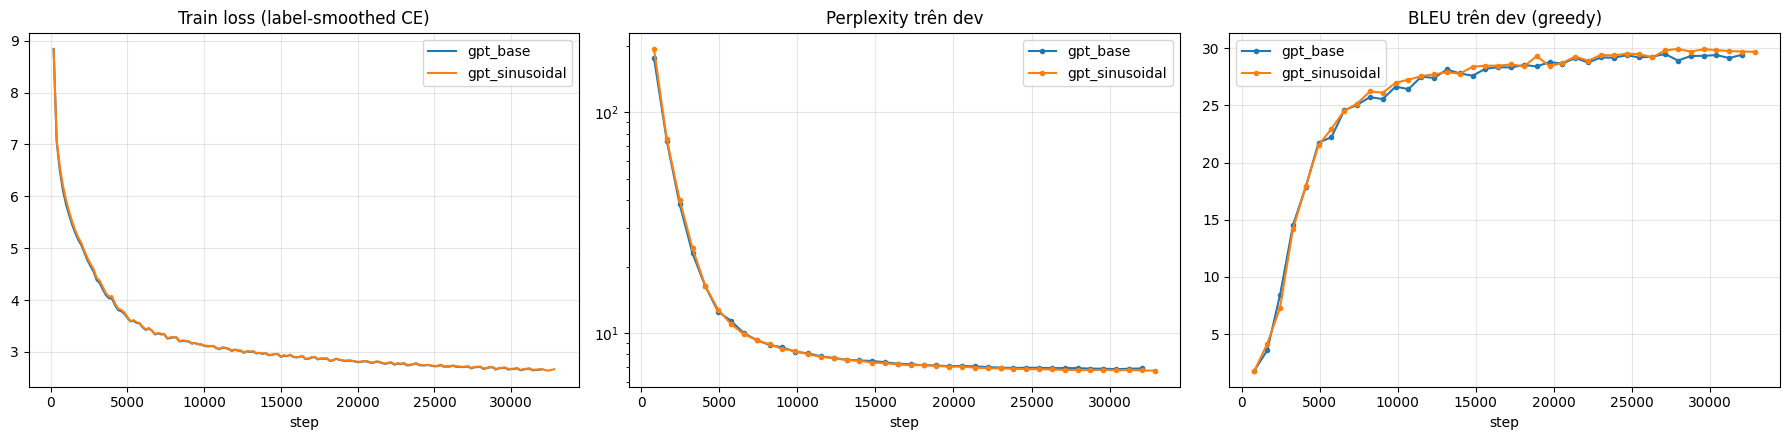

In [10]:
#@title 📈 Đường cong huấn luyện (loss, perplexity dev, BLEU dev)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for name in EXPERIMENTS:
    f = paths.checkpoints / name / "history.csv"
    if not f.exists():
        continue
    h = pd.read_csv(f)
    tr = h.dropna(subset=["train_loss"]) if "train_loss" in h else h.iloc[0:0]
    ev = h.dropna(subset=["score"]) if "score" in h else h.iloc[0:0]
    ax[0].plot(tr["step"], tr["train_loss"], label=name)
    if "dev_ppl" in ev:
        ax[1].plot(ev["step"], ev["dev_ppl"], marker="o", ms=3, label=name)
    ax[2].plot(ev["step"], ev["score"], marker="o", ms=3, label=name)
ax[0].set(title="Train loss (label-smoothed CE)", xlabel="step"); ax[1].set(title="Perplexity trên dev", xlabel="step", yscale="log")
ax[2].set(title="BLEU trên dev (greedy)", xlabel="step")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(paths.figures / "03_learning_curves.png", dpi=150); plt.show()

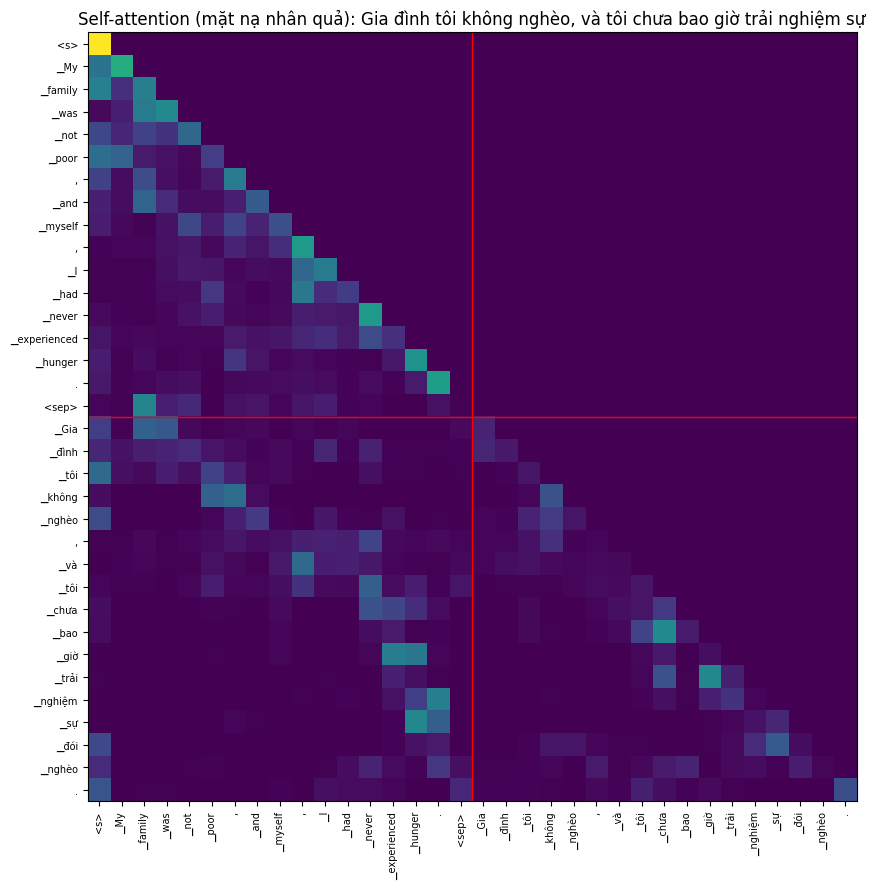

In [11]:
#@title 🔍 Trực quan hoá self-attention của GPT (lớp cuối): phần đích "nhìn" vào phần nguồn
model, _ = build_model(EXPERIMENTS[MAIN])
best = torch.load(paths.checkpoints / MAIN / "best.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(best["model"]); model.eval()
sent = [s for s in test_src_txt if 6 <= len(s.split()) <= 14][0]
src_ids = tok.encode([sent])[0]
hyp = DEC.gpt_generate_batch(model, [src_ids], tok.sep_id, beam_size=1, device=DEVICE)[0]
seq = torch.tensor([[D.BOS_ID] + src_ids + [tok.sep_id] + hyp], device=DEVICE)
with torch.no_grad():
    model(seq, need_weights=True)
w = model.layers[-1].self_attn.last_attn[0].mean(0).float().cpu().numpy()
pieces = [tok.sp.id_to_piece(i) for i in seq[0].tolist()]
plt.figure(figsize=(11, 9)); plt.imshow(w, cmap="viridis")
plt.xticks(range(len(pieces)), pieces, rotation=90, fontsize=7); plt.yticks(range(len(pieces)), pieces, fontsize=7)
plt.axvline(len(src_ids) + 1.5, color="r", lw=1); plt.axhline(len(src_ids) + 1.5, color="r", lw=1)
plt.title("Self-attention (mặt nạ nhân quả): " + tok.decode([hyp])[0][:60])
plt.tight_layout(); plt.savefig(paths.figures / "03_gpt_attention.png", dpi=150); plt.show()
del model; free_memory()

In [12]:
#@title 📋 Tóm tắt
rows = []
for name, r in results.items():
    if r is None:
        continue
    for f in sorted(paths.predictions.glob(f"{name}_beam*.vi.txt")):
        system = f.name.replace(".vi.txt", "")
        meta = load_json(paths.predictions / f"{system}.meta.json")
        hyps = read_lines(f)
        rows.append({"hệ thống": system, "tham số (M)": round(r["params"] / 1e6, 1), "BLEU dev (greedy)": round(r["best_dev_bleu"], 2),
                     "BLEU test": round(M.quick_bleu(hyps, test_ref), 2), "beam": meta["beam"],
                     "thời gian train": fmt_seconds(r["train_time_s"]), "thời gian dịch (s)": round(meta["decode_time_s"], 1)})
df = pd.DataFrame(rows)
df.to_csv(paths.results / "03_table.csv", index=False)
print("Đánh giá đầy đủ (chrF++, TER, METEOR, COMET, BERTScore, kiểm định thống kê) ở notebook 06.")
df

Đánh giá đầy đủ (chrF++, TER, METEOR, COMET, BERTScore, kiểm định thống kê) ở notebook 06.


,hệ thống,tham số (M),BLEU dev (greedy),BLEU test,beam,thời gian train,thời gian dịch (s)
0,gpt_base_beam1,40.0,29.49,28.79,1,1h30m36s,17.5
1,gpt_base_beam4,40.0,29.49,30.00,4,1h30m36s,53.6
2,gpt_sinusoidal_beam4,39.7,29.93,30.49,4,1h32m43s,56.0


✅ Xong. Tiếp theo: **04_pretrained_encoder_decoder.ipynb**.